**Eye-Tracking & Neurocognitive Intelligence | Eye-Movement Modelling & Advanced AI | Presented by: Reza Saadatyar (2026)**

**4 | GRU and Transformer Encoder**

![Independent temporal model architectures and validation within source-participant partitions](../../images/04_gru_and_transformer_models.svg)

**Objective:** Train and compare Gated Recurrent Unit (GRU) and Compact Transformer Encoder as independent compact temporal gaze classifiers. Each model has its own training cell, parameter count, learning curves, Validation confusion matrix and numerical record-level evaluation.

**Source and partitions:** The original GazeBase recording/task identities, four motion channels and train-only normalisation are fixed by Notebook 01. No Test results or Test-driven hyperparameters are used. Training and Validation windows inherit their source recording labels but **are not independent people**.

**Scope:** Settings are fixed to small models and at most eight epochs with Validation-based early stopping. The ten-person run is a **pilot**, and results cannot establish model superiority or unseen-person generalisation across the wider GazeBase dataset. All displayed metrics are pending execution.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_movement_modelling")

# -------------------- 2. Temporal Training and Evaluation --------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from IPython.display import display
from core.stage_outputs import ensure_stage_inputs
from core.output_download import download_outputs_from_colab
from core.plot_style import plot_style, save_figure

# ------------------------- 3. Study Model Utilities --------------------------
from s2_data import (
    TASKS, load_protocol, load_windows, verify_temporal_source_alignment,
)
from s2_training import fit_temporal
from s2_metrics import metric_row

# ----------------------------- 4. Output Folder ------------------------------
output_dir = root / "eye_movement_modelling" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Eye-Movement Modelling temporal outputs:", output_dir)


Repository updated.
Eye-Movement Modelling temporal outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output


**02. Recover Normalised Windows and Frozen Participant Groups**

Reuse the same `01_sequence_windows.npz`, `01_split_assignments.csv` and `01_protocol.csv` as the classical comparison. Stage 01 computed normalisation moments **from Train windows only**; each temporal model receives exactly the same precomputed values. All four models evaluate by averaging per-window class probabilities **within each original source recording**.

Read the scientific configuration and print sample/window counts; no extra Trial/Validation/Test splitting or random per-window Train–Test partition is performed here.


In [3]:
# ==================== 02. Recover Frozen Temporal Inputs =====================

# -------------------- 1. Restore Explicit Stage 01 Files ---------------------
ensure_stage_inputs(output_dir, 1, (
    "01_sequence_windows.npz",
    "01_split_assignments.csv", "01_protocol.csv",
))
windows = load_windows(output_dir / "01_sequence_windows.npz")
split = pd.read_csv(
    output_dir / "01_split_assignments.csv",
    dtype={"record_id": str, "participant_id": str},
)
protocol = load_protocol(output_dir / "01_protocol.csv")
if windows["x"].shape[1:] != (
    protocol["window_samples"], len(protocol["temporal_channels"]),
):
    raise ValueError("Sequence data does not match the saved source protocol")

# -------------------------- 2. Display Data Support --------------------------
record_roles = dict(zip(split.record_id, split.split))
alignment_counts = verify_temporal_source_alignment(windows, split)
roles = np.array([record_roles[str(r)] for r in windows["record_id"]])
print("Verified window counts by participant partition:", alignment_counts)
validation_people = split.loc[
    split.split.eq("validation"), "participant_id",
].nunique()
print("Study mode:", protocol["purpose"])
print("Sequence tensor:", windows["x"].shape)
print("Train/Validation/Test window counts:")
display(pd.Series(roles).value_counts().rename("n_windows").to_frame())
print("Independent Validation participants:", validation_people)
reported = []


Verified window counts by participant partition: {'train': 576, 'validation': 192, 'test': 192}
Study mode: pilot
Sequence tensor: (960, 256, 4)
Train/Validation/Test window counts:


,n_windows
train,576
test,192
validation,192


Independent Validation participants: 2


**03. Gated Recurrent Unit (GRU) Architecture, Training and Validation**

**Architecture:** A single-layer GRU reads the sequential gaze channels and passes its final state to a four-class head. The input is a fixed-length tensor of consecutive, source-valid gaze samples with four train-normalised channels. Use this model's separate cell to display training loss, Validation loss, selected epoch, parameter count, record-level Macro F1 and the Validation confusion matrix.

**Caution:** Validation is a small participant-level group. Its metric is for provisional selection only, not an independently replicated result.


Model: gru
Best epoch: 1
Trainable parameters: 3780


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,epoch,train_loss,validation_window_loss
0,gru,validation,8,2,0.250,0.100000,0.250,1,1.403440,1.399047
1,gru,validation,8,2,0.125,0.083333,0.125,2,1.391850,1.392785
2,gru,validation,8,2,0.125,0.083333,0.125,3,1.386097,1.389050
3,gru,validation,8,2,0.125,0.083333,0.125,4,1.383150,1.386599


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,gru,validation,8,2,0.25,0.1,0.25


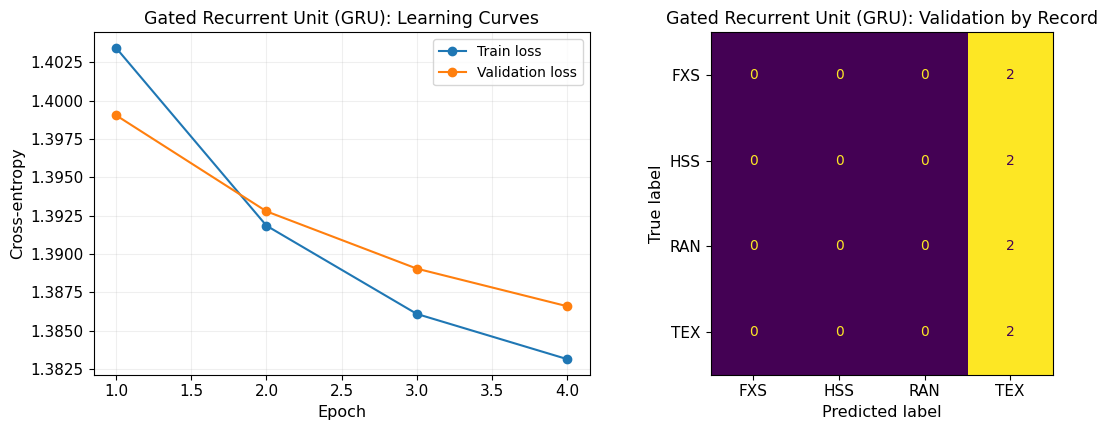

In [4]:
# =================== 03. Train Gated Recurrent Unit (GRU) ====================

# --------------------- 1. Fit on Train Participants Only ---------------------
model_name = "gru"
history, predictions, info = fit_temporal(
    model_name, windows, split, output_dir / f"04_gru.pt",
    seed=protocol["split_seed"], epochs=8, patience=3,
    batch_size=64,
)
history.to_csv(output_dir / f"04_gru_history.csv", index=False)
predictions.to_csv(
    output_dir / f"04_gru_validation_predictions.csv", index=False,
)
print("Model:", model_name)
print("Best epoch:", info["best_epoch"])
print("Trainable parameters:", info["parameters"])
display(history.tail(8))

# --------------------- 2. Report Record-Level Validation ---------------------
result = metric_row(
    predictions["target_index"], predictions["pred_index"],
    model=model_name, partition="validation",
    n_participants=validation_people,
)
reported.append(result)
display(pd.DataFrame([result]))

# ------------------ 3. Display Learning and Error Evidence -------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(history["epoch"], history["train_loss"],
             marker="o", label="Train loss")
axes[0].plot(history["epoch"], history["validation_window_loss"],
             marker="o", label="Validation loss")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy",
            title="Gated Recurrent Unit (GRU): Learning Curves")
axes[0].grid(alpha=0.2)
axes[0].legend()
matrix = confusion_matrix(
    predictions.target_index, predictions.pred_index,
    labels=range(len(TASKS)),
)
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=axes[1], colorbar=False, values_format="d",
)
axes[1].set_title("Gated Recurrent Unit (GRU): Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"04_gru_evaluation.png")
plt.show()


**04. Compact Transformer Encoder Architecture, Training and Validation**

**Architecture:** Average-pooling by four reduces the source window length before two encoder blocks with four attention heads; the representation is pooled for classification. Use the same time windows, group split, seed, optimiser family and maximum epoch budget as the preceding model, while preserving model-specific mechanisms.

The model receives its own training log, selected checkpoint, loss curves, Validation probability table and confusion matrix. Attention weights or feature maps are **not automatically faithful explanations** of task decisions.


Model: transformer
Best epoch: 2
Trainable parameters: 33764


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,epoch,train_loss,validation_window_loss
0,transformer,validation,8,2,0.250,0.100000,0.250,1,1.395828,1.381719
1,transformer,validation,8,2,0.500,0.375000,0.500,2,1.384938,1.376331
2,transformer,validation,8,2,0.375,0.277778,0.375,3,1.370836,1.365719
3,transformer,validation,8,2,0.375,0.277778,0.375,4,1.361787,1.356290
4,transformer,validation,8,2,0.375,0.277778,0.375,5,1.345792,1.341855


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,transformer,validation,8,2,0.5,0.375,0.5


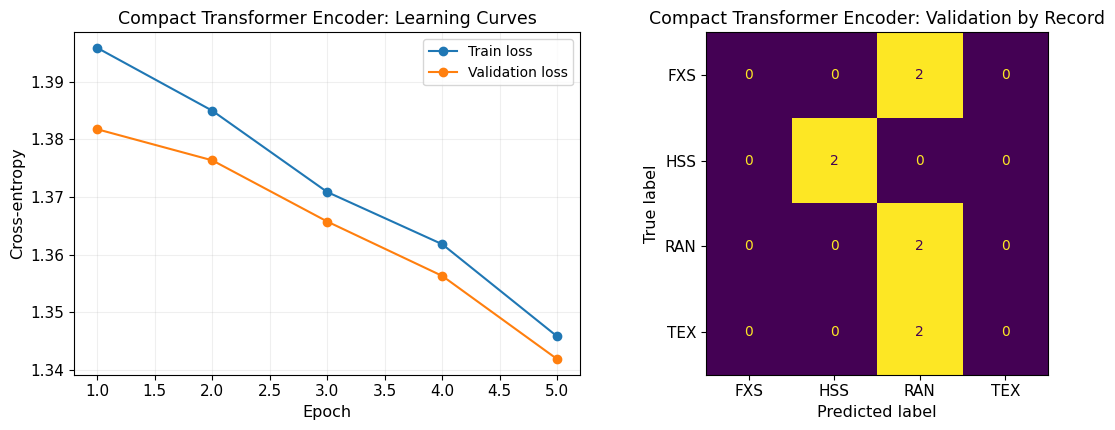

In [5]:
# =================== 04. Train Compact Transformer Encoder ===================

# --------------------- 1. Fit on Train Participants Only ---------------------
model_name = "transformer"
history, predictions, info = fit_temporal(
    model_name, windows, split, output_dir / f"04_transformer.pt",
    seed=protocol["split_seed"], epochs=8, patience=3,
    batch_size=64,
)
history.to_csv(output_dir / f"04_transformer_history.csv", index=False)
predictions.to_csv(
    output_dir / f"04_transformer_validation_predictions.csv", index=False,
)
print("Model:", model_name)
print("Best epoch:", info["best_epoch"])
print("Trainable parameters:", info["parameters"])
display(history.tail(8))

# --------------------- 2. Report Record-Level Validation ---------------------
result = metric_row(
    predictions["target_index"], predictions["pred_index"],
    model=model_name, partition="validation",
    n_participants=validation_people,
)
reported.append(result)
display(pd.DataFrame([result]))

# ------------------ 3. Display Learning and Error Evidence -------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(history["epoch"], history["train_loss"],
             marker="o", label="Train loss")
axes[0].plot(history["epoch"], history["validation_window_loss"],
             marker="o", label="Validation loss")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy",
            title="Compact Transformer Encoder: Learning Curves")
axes[0].grid(alpha=0.2)
axes[0].legend()
matrix = confusion_matrix(
    predictions.target_index, predictions.pred_index,
    labels=range(len(TASKS)),
)
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=axes[1], colorbar=False, values_format="d",
)
axes[1].set_title("Compact Transformer Encoder: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"04_transformer_evaluation.png")
plt.show()


**05. Compare the Two Temporal Models on Record-Level Validation**

The comparison uses equal records and the same independent Validation people. Report fixed-class Macro F1, Balanced Accuracy, accuracy and model parameter count alongside separate training histories. Even if one model scores higher, the small ten-person pilot cannot establish reliable architectural superiority.

Notebook 05 later compares these scores to the feature-based and other temporal families. It makes the selected-model decision from **Validation only**, before opening Test results.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
1,transformer,validation,8,2,0.50,0.375,0.50
0,gru,validation,8,2,0.25,0.100,0.25


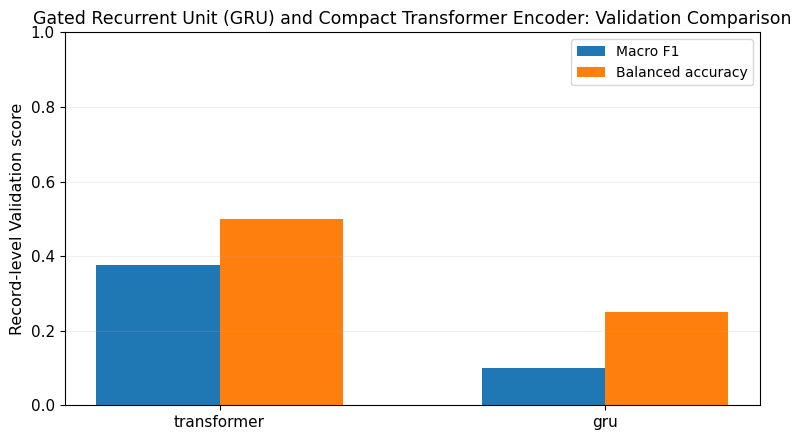

In [6]:
# ====================== 05. Compare Temporal Validation ======================

# --------------------- 1. Save Shared Validation Metrics ---------------------
metrics = pd.DataFrame(reported).sort_values(
    ["macro_f1", "balanced_accuracy", "model"],
    ascending=[False, False, True],
)
metrics.to_csv(
    output_dir / "04_neural_validation_metrics.csv", index=False,
)
display(metrics)

# --------------------- 2. Plot Independent Model Scores ----------------------
fig, ax = plt.subplots(figsize=(7.8, 4.5))
pos = np.arange(len(metrics))
ax.bar(pos - 0.16, metrics["macro_f1"], 0.32, label="Macro F1")
ax.bar(pos + 0.16, metrics["balanced_accuracy"], 0.32,
       label="Balanced accuracy")
ax.set_xticks(pos, metrics["model"])
ax.set(ylabel="Record-level Validation score", ylim=(0, 1),
       title="Gated Recurrent Unit (GRU) and Compact Transformer Encoder: Validation Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "04_model_comparison.png")
plt.show()


**06. Interpretation and Local Model Outputs**

The notebook saves the two model state-dict checkpoints, their Training/Validation histories, record-level Validation predictions and independent assessment plots, plus one common metrics table. All trainable parameters were selected **before Test evaluation**.

Next, Notebook 05 loads the saved weights without refitting or looking at Test-driven feedback; Test predictions should only be computed in that final stage. Large checkpoints and generated ZIPs are local by default and covered by the Git file-size policy.


In [7]:
# ===================== 06. Export Temporal Model Outputs =====================

# ---------------------- 1. Display Saved Model Evidence ----------------------
print("Participant mode:", protocol["purpose"])
print("Validation metrics:", output_dir /
      "04_neural_validation_metrics.csv")
for name in ("gru", "transformer"):
    print("Model state:", output_dir / f"04_{name}.pt")
    print("Training figure:", output_dir / f"04_{name}_evaluation.png")

# -------------------- 2. Package Stage-Owned Output Files --------------------
download_outputs_from_colab("eye_movement_modelling/output", "04")


Participant mode: pilot
Validation metrics: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/04_neural_validation_metrics.csv
Model state: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/04_gru.pt
Training figure: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/04_gru_evaluation.png
Model state: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/04_transformer.pt
Training figure: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/04_transformer_evaluation.png
------------------------------------------------------------------------
Notebook 04
Files packaged: 10
  + 04_gru.pt
  + 04_gru_evaluation.png
  + 04_gru_history.csv
  + 04_gru_validation_predictions.csv
  + 04_model_comparison.png
  + 04_neural_validation_metrics.csv
  + 04_transformer.pt
  + 04_transformer_evaluation.png
  + 04_transformer_history.csv
  + 04_transformer_validat